AVERAGE SYMBOL ENERGY BEFORE AND AFTER NORMALIZATION
Mapping: GRAY
QPSK     | Before =   4.0000 | After =   1.0000
8-PSK    | Before =   4.0000 | After =   1.0000
16-QAM   | Before =  10.0000 | After =   1.0000
64-QAM   | Before =  42.0000 | After =   1.0000

Expected normalized average symbol energy: Es = 1


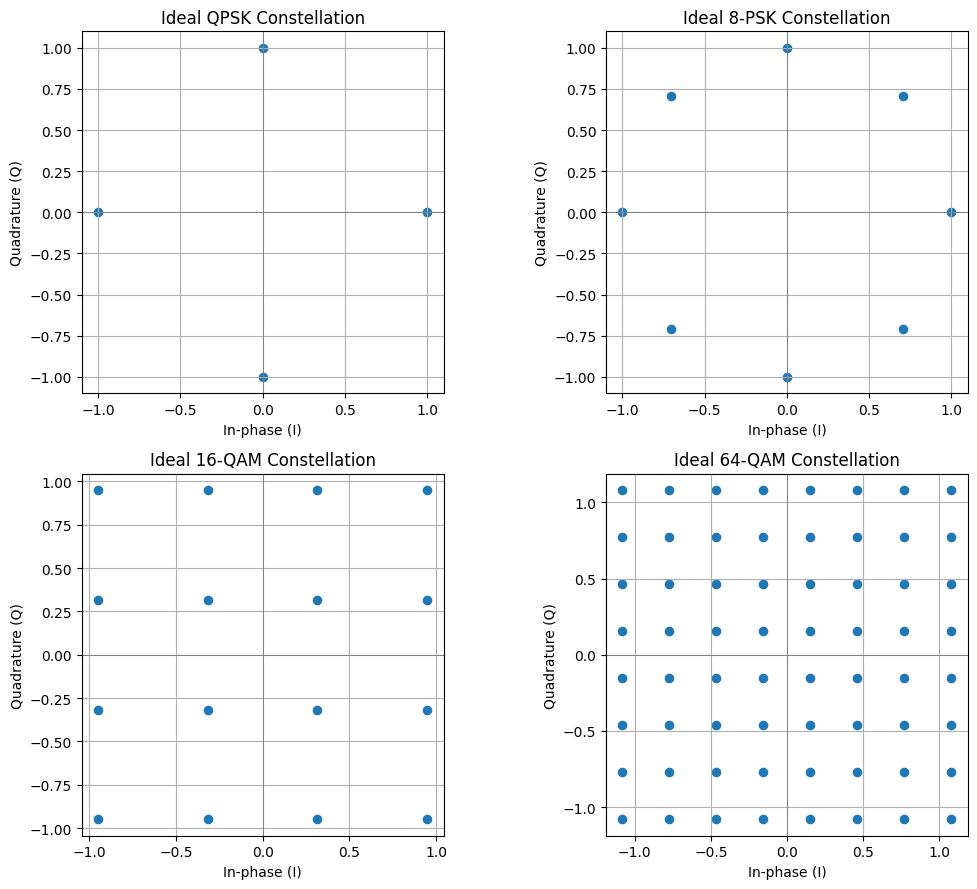

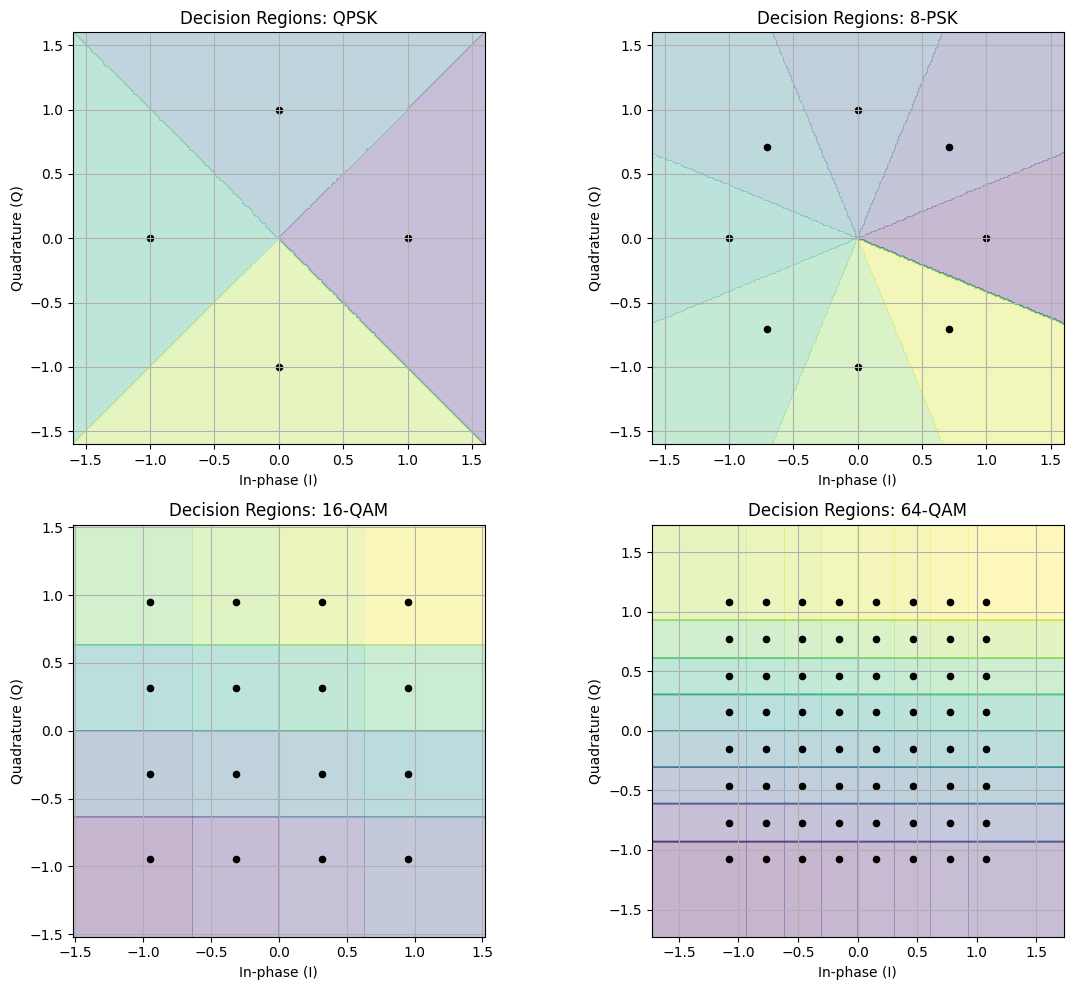

QPSK     | SNR =  0 dB | BER = 1.577600e-01 | SER = 2.904700e-01
QPSK     | SNR =  5 dB | BER = 3.792500e-02 | SER = 7.437000e-02
QPSK     | SNR = 10 dB | BER = 7.600000e-04 | SER = 1.520000e-03
QPSK     | SNR = 20 dB | BER = 0.000000e+00 | SER = 0.000000e+00
8-PSK    | SNR =  0 dB | BER = 2.421200e-01 | SER = 5.778000e-01
8-PSK    | SNR =  5 dB | BER = 1.172300e-01 | SER = 3.336600e-01
8-PSK    | SNR = 10 dB | BER = 2.943333e-02 | SER = 8.827000e-02
8-PSK    | SNR = 20 dB | BER = 0.000000e+00 | SER = 0.000000e+00
16-QAM   | SNR =  0 dB | BER = 2.878925e-01 | SER = 7.409000e-01
16-QAM   | SNR =  5 dB | BER = 1.647300e-01 | SER = 5.384800e-01
16-QAM   | SNR = 10 dB | BER = 5.933500e-02 | SER = 2.239100e-01
16-QAM   | SNR = 20 dB | BER = 5.000000e-06 | SER = 2.000000e-05
64-QAM   | SNR =  0 dB | BER = 3.592233e-01 | SER = 9.227400e-01
64-QAM   | SNR =  5 dB | BER = 2.635733e-01 | SER = 8.504700e-01
64-QAM   | SNR = 10 dB | BER = 1.524900e-01 | SER = 6.739900e-01
64-QAM   | SNR = 20 dB | 

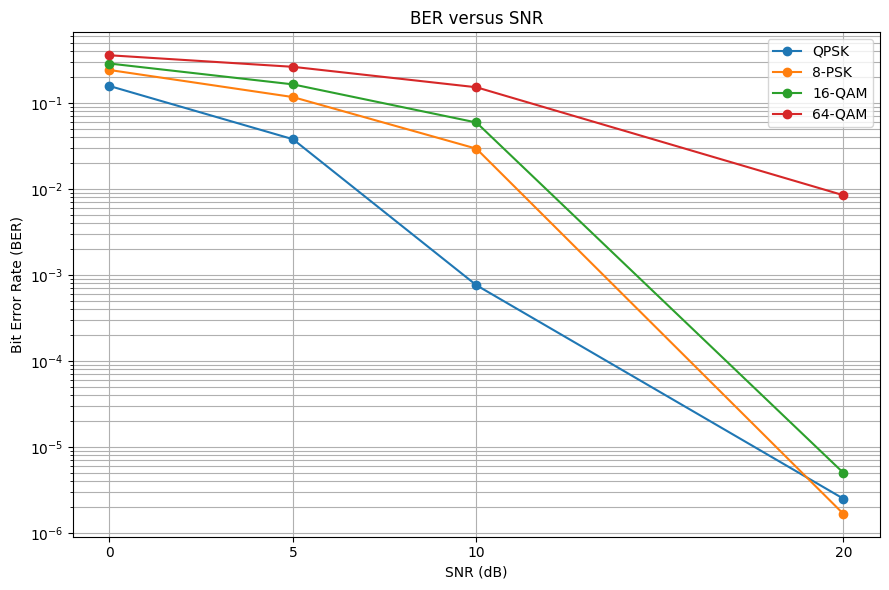

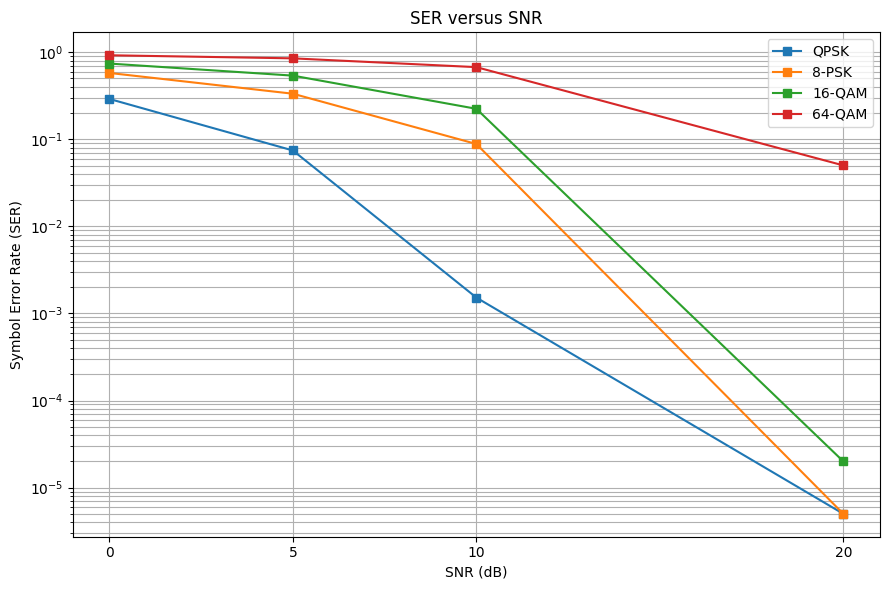

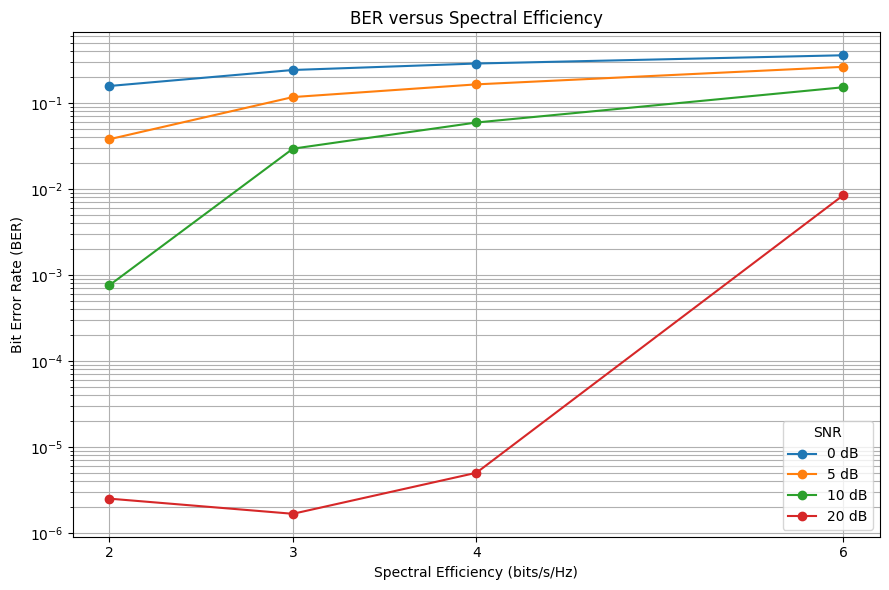


SPECTRAL EFFICIENCY
-----------------------------------
QPSK    : 2 bits/s/Hz
8-PSK   : 3 bits/s/Hz
16-QAM  : 4 bits/s/Hz
64-QAM  : 6 bits/s/Hz


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# EXPERIMENT 11: M-PSK AND M-QAM
# Gray/Binary Mapping, Energy Normalization, BER and SER
# ============================================================

np.random.seed(42)

MODULATIONS = {
    "QPSK": ("PSK", 4),
    "8-PSK": ("PSK", 8),
    "16-QAM": ("QAM", 16),
    "64-QAM": ("QAM", 64)
}

SNR_DB = [0, 5, 10, 20]
N_SYMBOLS = 100_000
MAPPING = "gray"       # Change to "binary" for binary mapping


# ------------------------------------------------------------
# 1. Binary and Gray labels
# ------------------------------------------------------------

def gray_code(n):
    return n ^ (n >> 1)


def integer_to_bits(value, nbits):
    return np.array(
        [(value >> k) & 1 for k in range(nbits - 1, -1, -1)],
        dtype=int
    )


def get_bits(value, nbits, mapping):
    if mapping == "gray":
        value = gray_code(value)
    return integer_to_bits(value, nbits)


# ------------------------------------------------------------
# 2. Generate ideal constellation points and bit labels
# ------------------------------------------------------------

def generate_constellation(name, mapping="gray"):
    modulation, M = MODULATIONS[name]
    k = int(np.log2(M))

    if modulation == "PSK":
        # Use radius 2 before normalization so that
        # the mandatory before/after energy check is meaningful.
        indices = np.arange(M)
        phases = 2 * np.pi * indices / M
        points = 2 * np.exp(1j * phases)

        labels = np.array([
            get_bits(i, k, mapping) for i in indices
        ])

    else:
        L = int(np.sqrt(M))
        levels = np.arange(-(L - 1), L, 2)

        points_list = []
        labels_list = []

        for q_index in range(L):
            for i_index in range(L):
                # I and Q coordinates
                point = levels[i_index] + 1j * levels[q_index]
                points_list.append(point)

                # Split the bits equally between I and Q.
                i_bits = get_bits(i_index, k // 2, mapping)
                q_bits = get_bits(q_index, k // 2, mapping)
                labels_list.append(np.concatenate((i_bits, q_bits)))

        points = np.array(points_list, dtype=complex)
        labels = np.array(labels_list, dtype=int)

    # Mandatory energy calculation before normalization
    energy_before = np.mean(np.abs(points) ** 2)

    # Normalize average symbol energy to Es = 1
    points = points / np.sqrt(energy_before)

    energy_after = np.mean(np.abs(points) ** 2)

    return points, labels, energy_before, energy_after


# ------------------------------------------------------------
# 3. Minimum Euclidean-distance detector
# ------------------------------------------------------------

def detect_symbols(received, constellation):
    distances = np.abs(
        received[:, None] - constellation[None, :]
    ) ** 2

    return np.argmin(distances, axis=1)


# ------------------------------------------------------------
# 4. AWGN simulation and BER/SER calculation
# ------------------------------------------------------------

def simulate(name, snr_db, mapping="gray", n_symbols=N_SYMBOLS):
    constellation, labels, _, _ = generate_constellation(
        name, mapping
    )

    M = len(constellation)
    k = int(np.log2(M))

    # Random transmitted symbol indices
    tx_indices = np.random.randint(0, M, n_symbols)
    tx_symbols = constellation[tx_indices]

    # Es = 1; complex AWGN variance = N0
    snr_linear = 10 ** (snr_db / 10)
    noise_variance = 1 / snr_linear

    noise = np.sqrt(noise_variance / 2) * (
        np.random.randn(n_symbols)
        + 1j * np.random.randn(n_symbols)
    )

    rx_symbols = tx_symbols + noise

    # Minimum-distance detection in chunks to save memory
    rx_indices = np.empty(n_symbols, dtype=int)
    chunk_size = 10_000

    for start in range(0, n_symbols, chunk_size):
        end = min(start + chunk_size, n_symbols)
        rx_indices[start:end] = detect_symbols(
            rx_symbols[start:end], constellation
        )

    # Symbol error rate
    ser = np.mean(rx_indices != tx_indices)

    # Compare the transmitted and detected bit labels
    tx_bits = labels[tx_indices]
    rx_bits = labels[rx_indices]

    ber = np.mean(tx_bits != rx_bits)

    return constellation, tx_symbols, rx_symbols, ber, ser


# ------------------------------------------------------------
# 5. Generate constellations and report numerical energy
# ------------------------------------------------------------

constellations = {}

print("=" * 68)
print("AVERAGE SYMBOL ENERGY BEFORE AND AFTER NORMALIZATION")
print("Mapping:", MAPPING.upper())
print("=" * 68)

for name in MODULATIONS:
    points, labels, before, after = generate_constellation(
        name, MAPPING
    )
    constellations[name] = (points, labels)

    print(
        f"{name:8s} | Before = {before:8.4f} | "
        f"After = {after:8.4f}"
    )

print("\nExpected normalized average symbol energy: Es = 1")


# ------------------------------------------------------------
# 6. Ideal constellation diagrams
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(11, 9))

for ax, name in zip(axes.flat, MODULATIONS):
    points, _ = constellations[name]

    ax.scatter(points.real, points.imag, s=35)
    ax.axhline(0, color="gray", linewidth=0.7)
    ax.axvline(0, color="gray", linewidth=0.7)
    ax.set_title(f"Ideal {name} Constellation")
    ax.set_xlabel("In-phase (I)")
    ax.set_ylabel("Quadrature (Q)")
    ax.grid(True)
    ax.set_aspect("equal", adjustable="box")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. Decision regions using minimum-distance detection
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, name in zip(axes.flat, MODULATIONS):
    points, _ = constellations[name]

    limit = 1.6 * np.max(
        np.maximum(np.abs(points.real), np.abs(points.imag))
    )

    grid = np.linspace(-limit, limit, 250)
    xx, yy = np.meshgrid(grid, grid)
    test_points = (xx + 1j * yy).ravel()

    region = detect_symbols(test_points, points).reshape(xx.shape)

    ax.contourf(
        xx, yy, region,
        levels=np.arange(len(points) + 1) - 0.5,
        alpha=0.3
    )
    ax.scatter(points.real, points.imag, c="black", s=20)
    ax.set_title(f"Decision Regions: {name}")
    ax.set_xlabel("In-phase (I)")
    ax.set_ylabel("Quadrature (Q)")
    ax.grid(True)
    ax.set_aspect("equal", adjustable="box")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. Run simulations at 0, 5, 10 and 20 dB
# ------------------------------------------------------------

results = {}

for name in MODULATIONS:
    results[name] = {"BER": [], "SER": []}

    for snr in SNR_DB:
        _, _, _, ber, ser = simulate(name, snr, MAPPING)

        results[name]["BER"].append(ber)
        results[name]["SER"].append(ser)

        print(
            f"{name:8s} | SNR = {snr:2d} dB | "
            f"BER = {ber:.6e} | SER = {ser:.6e}"
        )


# ------------------------------------------------------------
# 9. BER versus SNR
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

for name in MODULATIONS:
    plt.semilogy(
        SNR_DB,
        np.maximum(results[name]["BER"], 0.5 / (N_SYMBOLS *
                    int(np.log2(MODULATIONS[name][1])))),
        marker="o",
        label=name
    )

plt.xlabel("SNR (dB)")
plt.ylabel("Bit Error Rate (BER)")
plt.title("BER versus SNR")
plt.xticks(SNR_DB)
plt.grid(True, which="both")
plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. SER versus SNR
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

for name in MODULATIONS:
    plt.semilogy(
        SNR_DB,
        np.maximum(results[name]["SER"], 0.5 / N_SYMBOLS),
        marker="s",
        label=name
    )

plt.xlabel("SNR (dB)")
plt.ylabel("Symbol Error Rate (SER)")
plt.title("SER versus SNR")
plt.xticks(SNR_DB)
plt.grid(True, which="both")
plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 11. BER versus spectral efficiency
# ------------------------------------------------------------

spectral_efficiency = {
    name: int(np.log2(M))
    for name, (_, M) in MODULATIONS.items()
}

plt.figure(figsize=(9, 6))

for snr_index, snr in enumerate(SNR_DB):
    ber_values = [
        max(
            results[name]["BER"][snr_index],
            0.5 / (
                N_SYMBOLS *
                int(np.log2(MODULATIONS[name][1]))
            )
        )
        for name in MODULATIONS
    ]

    efficiencies = [
        spectral_efficiency[name] for name in MODULATIONS
    ]

    plt.semilogy(
        efficiencies, ber_values,
        marker="o", label=f"{snr} dB"
    )

plt.xlabel("Spectral Efficiency (bits/s/Hz)")
plt.ylabel("Bit Error Rate (BER)")
plt.title("BER versus Spectral Efficiency")
plt.xticks([2, 3, 4, 6])
plt.grid(True, which="both")
plt.legend(title="SNR")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 12. Print spectral efficiency
# ------------------------------------------------------------

print("\nSPECTRAL EFFICIENCY")
print("-" * 35)

for name in MODULATIONS:
    print(
        f"{name:8s}: "
        f"{spectral_efficiency[name]} bits/s/Hz"
    )